## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Anderson Varela, Julian Sanchez, Juan pablo y Gabriel baron "
carnet = carnet anderson,1000113984,carnet jp, carnet gabriel


## 1) Descripción del problema **[1 pts]**
El centro de cómputo requiere un sistema para administrar y procesar tareas de manera eficiente basándose en su nivel de urgencia o prioridad numérica. Para lograrlo, se debe implementar una estructura de datos Max-Heap (Montículo Máximo) utilizando únicamente un arreglo lineal. Esto garantiza que la tarea con mayor prioridad se ubique siempre en la raíz y pueda ser consultada, extraída o ingresada con eficiencia temporal óptima, culminando con un algoritmo de ordenamiento manual (HeapSort).

Entradas

Cantidad de tareas ($n$): Número entero que indica cuántas tareas se van a registrar.

Datos por tarea:

Código: Cadena de texto identificadora (ej. T01).

Nombre: Cadena de texto con la descripción de la tarea (ej. Compilar proyecto).

Prioridad: Número entero que define la urgencia (a mayor número, mayor prioridad).

Operaciones interactivas: Consulta de máximo (MAXIMUM), extracción (EXTRACT-MAX), e inserción de nuevas tareas.

Salidas

Lista original de prioridades y tareas ingresadas.

Arreglo transformado en Max-Heap y representación gráfica sencilla en forma de árbol binario.

Resultado de la consulta de la tarea de mayor prioridad.

Información de la tarea procesada y estado actualizado del Heap tras la extracción.

Estado del Heap tras la inserción de una nueva tarea.

Lista ordenada de prioridades obtenida mediante el algoritmo manual HeapSort.

## 2) Requerimientos **[2 pts]**

Lista requerimientos

FUNCIONALES:

RF01 (Registro): Permitir al usuario ingresar $n$ tareas solicitando su código, nombre y prioridad, almacenándolas en el orden original.

RF02 (Construcción del Heap): Implementar de forma manual las funciones MAX-HEAPIFY y BUILD-MAX-HEAP para transformar el arreglo en un Max-Heap válido.

RF03 (Representación Visual): Mostrar el arreglo convertido en Max-Heap junto con una representación esquemática en forma de árbol en consola.

RF04 (Consulta - MAXIMUM): Implementar la función para visualizar la tarea en la raíz del Max-Heap sin eliminarla.

RF05 (Extracción - EXTRACT-MAX): Implementar la extracción de la raíz, mostrando la tarea procesada y reorganizando el Heap automáticamente.

RF06 (Inserción): Permitir agregar una nueva tarea al sistema conservando la propiedad estructural del Max-Heap.

RF07 (HeapSort): Implementar el algoritmo de ordenamiento manual basado en Max-Heap sin utilizar las funciones nativas sort() o sorted().

NO FUNCIONALES:

RNF01 (Estructura de datos): El Max-Heap debe estructurarse estrictamente sobre un arreglo unidimensional (lista en Python) sin utilizar clases con nodos o punteros enlazados.

RNF02 (Restricción de librerías): Está prohibido el uso de la librería estándar heapq.

RNF03 (Restricción de funciones): Está prohibido el uso de los métodos de ordenamiento nativos sort() y sorted().

RNF04 (Usabilidad): El programa debe presentar una interfaz por consola clara que ejecute secuencialmente los 5 puntos solicitados utilizando al menos 6 tareas para la prueba final.



## 3) Historias de usuario **[2 pts]**
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.


## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general

4.1 Diagrama de casos de uso
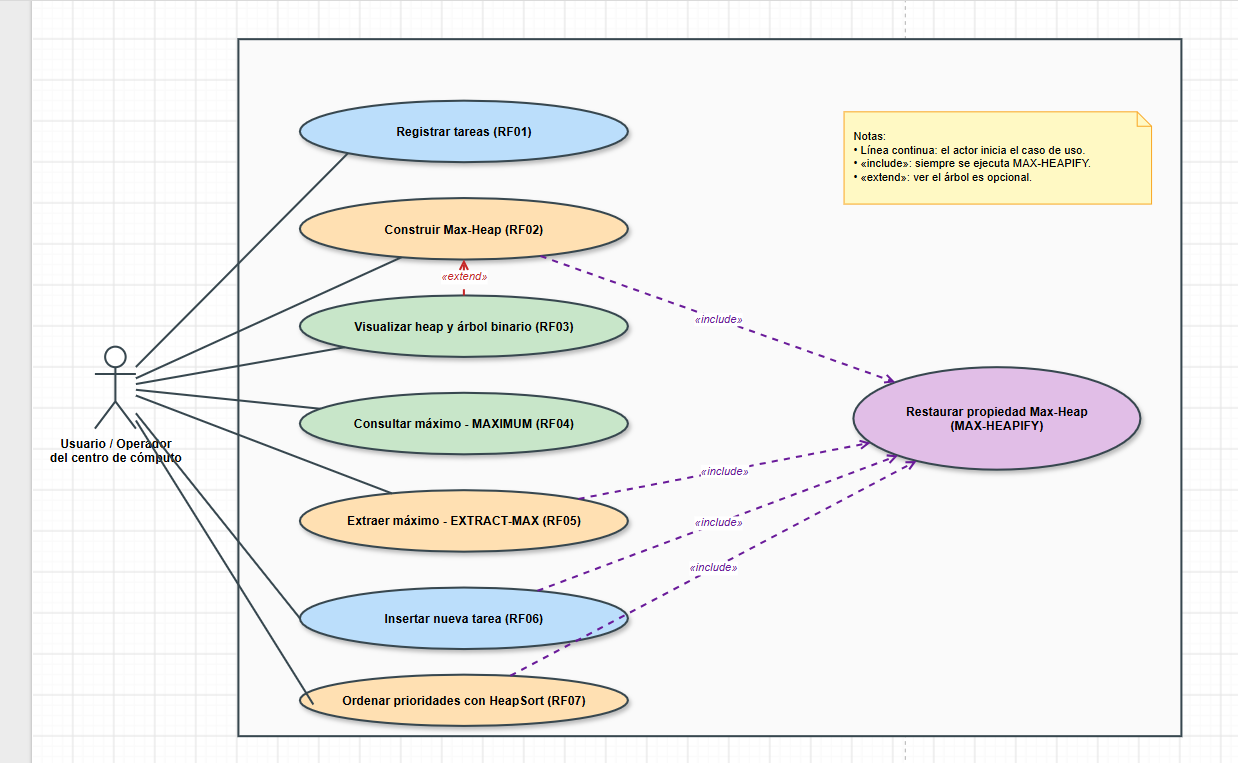

Para este diagrama partimos de los requerimientos funcionales que pusimos en la sección 2. Cada uno de los siete (RF01 a RF07) quedó como un caso de uso, y el único actor es el usuario que maneja el programa por consola, que sería el operador del centro de cómputo.

El usuario puede hacer siete cosas con el sistema. Primero registra las tareas con su código, nombre y prioridad (RF01). Luego esas tareas se organizan en un Max-Heap (RF02) y, si quiere, puede ver cómo quedó el arreglo y el árbol (RF03). También puede consultar cuál es la tarea con mayor prioridad sin sacarla (RF04), extraerla para procesarla (RF05), insertar una tarea nueva (RF06) y, al final, obtener las prioridades ordenadas con HeapSort (RF07).

Dibujamos además un caso de uso interno, “Restaurar propiedad Max-Heap”, que corresponde a la función MAX-HEAPIFY. Lo conectamos con flechas «include» desde construir el heap, extraer el máximo, insertar y HeapSort, porque en nuestro código todas esas operaciones tienen que llamarlo para que el heap siga siendo válido. Así evitamos repetirlo en cada una. La relación «extend» entre visualizar y construir indica que mostrar el árbol es opcional: el heap se puede construir sin mostrarlo.

Los colores solo sirven para agrupar: azul para registrar e insertar datos, verde para consultar, naranja para el procesamiento del heap y morado para el caso de uso interno.


4.2 Diagrama de secuencia
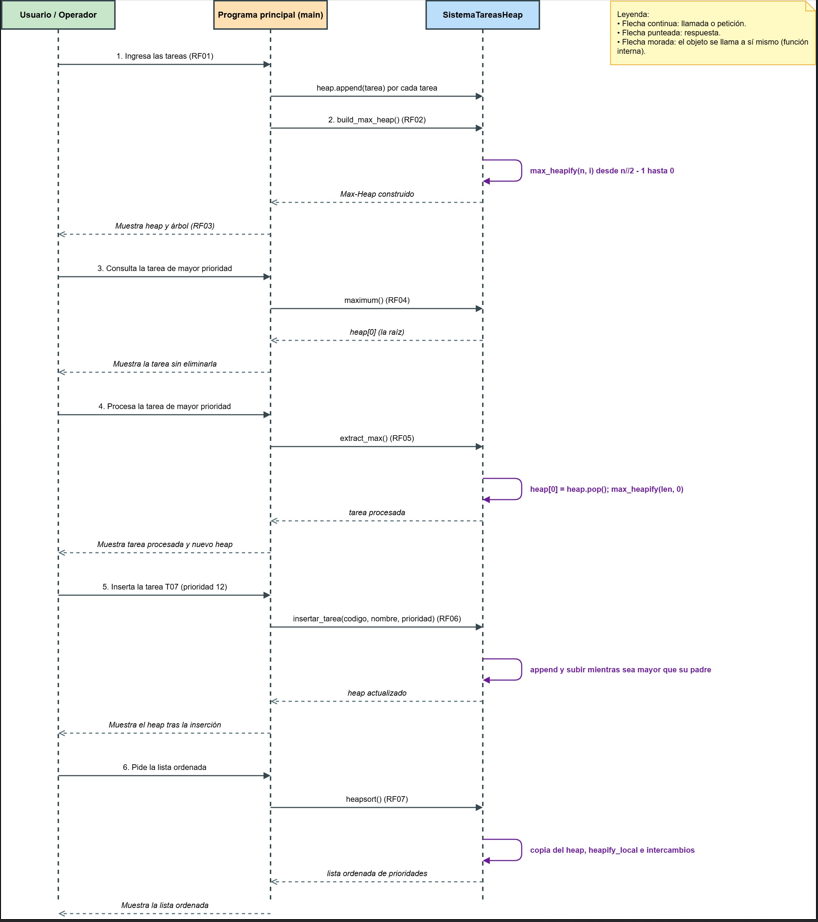

El diagrama de secuencia representa el flujo completo de la prueba final del programa. El usuario interactúa con el programa principal, que a su vez invoca los métodos de la clase SistemaTareasHeap. Primero se registran las tareas y se construye el Max-Heap, donde el sistema llama internamente a max_heapify desde la mitad del arreglo hasta la raíz. Luego se consulta la tarea de mayor prioridad con maximum(), que solo devuelve la raíz, y se procesa con extract_max(), que además reorganiza el heap. Después se inserta la tarea T07, que sube por el arreglo hasta quedar en su posición, y por último heapsort() trabaja sobre una copia del heap y devuelve la lista de prioridades ordenada. Las flechas punteadas son las respuestas de cada operación.

### 5) Análisis de complejidad **[15 pts]**
Incluye:
Un caso para cada funcion de busqueda
altura del heap, extract, insert, increase key, priority queue = O(log n)

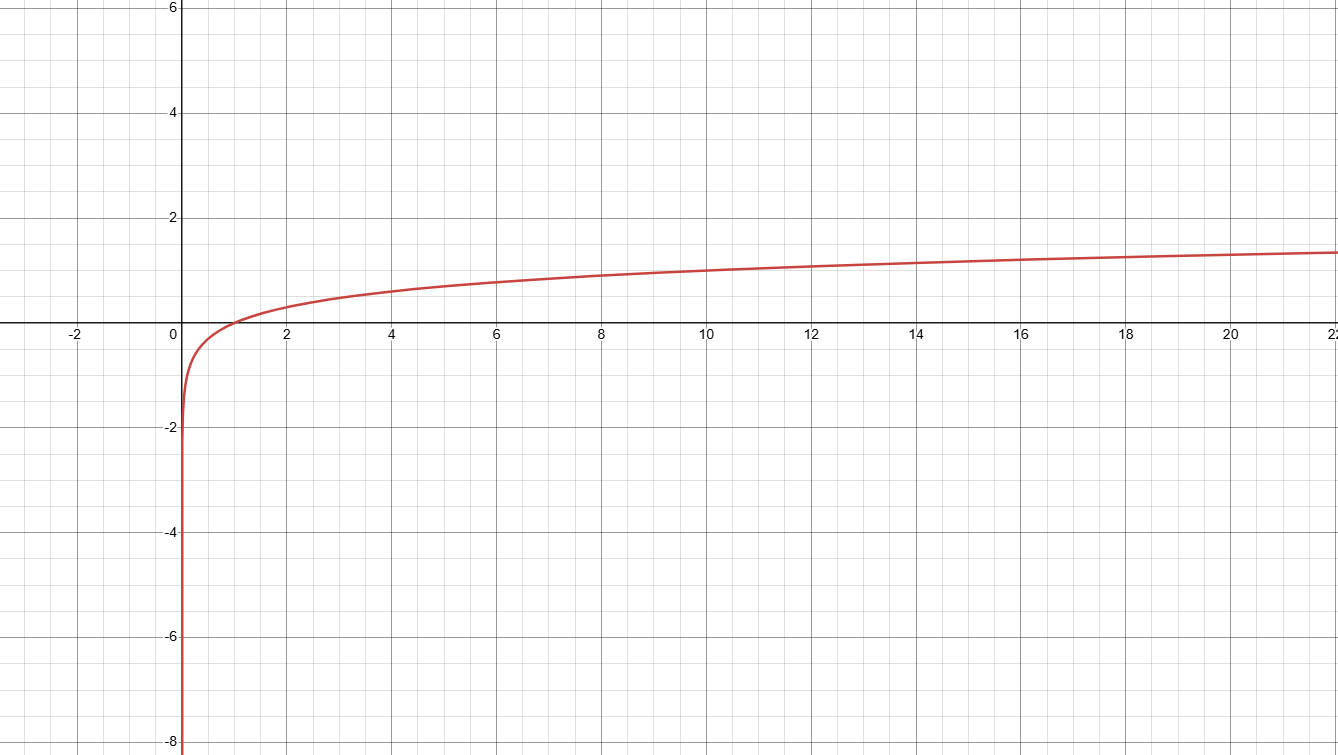

heapsort= O(nlogn)

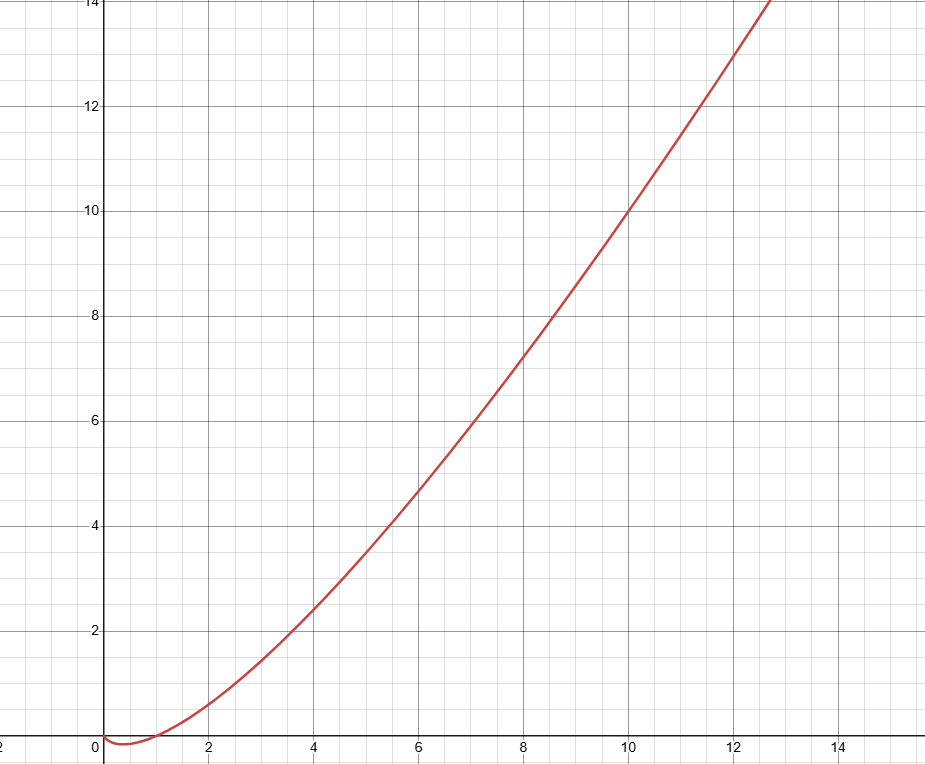

Build max heap= O(n)

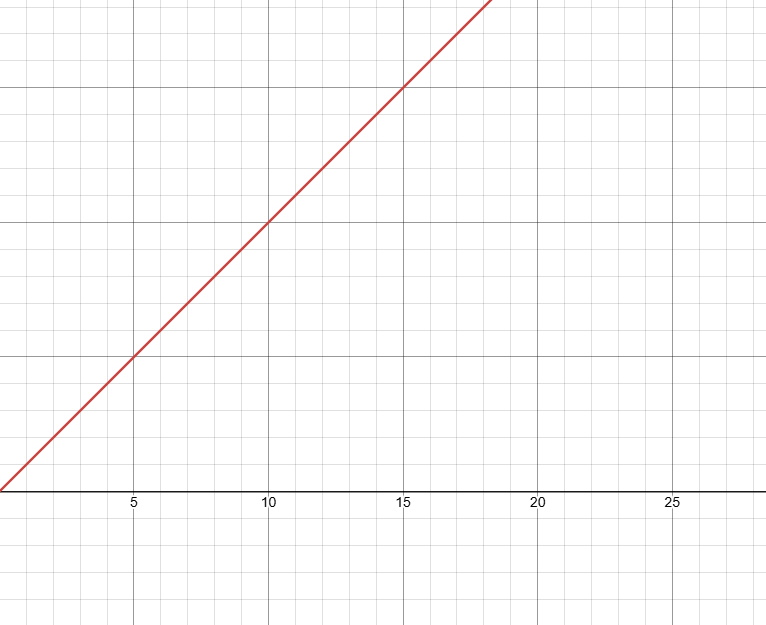



## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [ ]:
class SistemaTareasHeap:
    def __init__(self):
        # Cada tarea se almacena como un diccionario dentro de un arreglo
        self.heap = []

    def _padre(self, i):
        return (i - 1) // 2

    def _izq(self, i):
        return 2 * i + 1

    def _der(self, i):
        return 2 * i + 2

    def max_heapify(self, n, i):
        """Implementación manual de MAX-HEAPIFY"""
        l = self._izq(i)
        r = self._der(i)
        mayor = i

        if l < n and self.heap[l]['prioridad'] > self.heap[mayor]['prioridad']:
            mayor = l
        if r < n and self.heap[r]['prioridad'] > self.heap[mayor]['prioridad']:
            mayor = r

        if mayor != i:
            self.heap[i], self.heap[mayor] = self.heap[mayor], self.heap[i]
            self.max_heapify(n, mayor)

    def build_max_heap(self):
        """Implementación manual de BUILD-MAX-HEAP"""
        n = len(self.heap)
        for i in range(n // 2 - 1, -1, -1):
            self.max_heapify(n, i)

    def maximum(self):
        """Implementación de MAXIMUM (consulta la raíz)"""
        if not self.heap:
            return None
        return self.heap[0]

    def extract_max(self):
        """Implementación de EXTRACT-MAX"""
        if not self.heap:
            return None
        if len(self.heap) == 1:
            return self.heap.pop()

        raiz = self.heap[0]
        self.heap[0] = self.heap.pop()
        self.max_heapify(len(self.heap), 0)
        return raiz

    def insertar_tarea(self, codigo, nombre, prioridad):
        """Inserta una nueva tarea manteniendo la propiedad del Max-Heap"""
        nueva_tarea = {'codigo': codigo, 'nombre': nombre, 'prioridad': prioridad}
        self.heap.append(nueva_tarea)
        i = len(self.heap) - 1

        # Subir el elemento si es mayor que su padre
        while i > 0 and self.heap[self._padre(i)]['prioridad'] < self.heap[i]['prioridad']:
            padre = self._padre(i)
            self.heap[i], self.heap[padre] = self.heap[padre], self.heap[i]
            i = padre

    def heapsort(self):
        """Implementación manual de HEAPSORT usando las prioridades"""
        heap_copia = [dict(t) for t in self.heap]
        n = len(heap_copia)

        def heapify_local(arr, size, i):
            l = 2 * i + 1
            r = 2 * i + 2
            largest = i
            if l < size and arr[l]['prioridad'] > arr[largest]['prioridad']:
                largest = l
            if r < size and arr[r]['prioridad'] > arr[largest]['prioridad']:
                largest = r
            if largest != i:
                arr[i], arr[largest] = arr[largest], arr[i]
                heapify_local(arr, size, largest)

        for i in range(n // 2 - 1, -1, -1):
            heapify_local(heap_copia, n, i)

        for i in range(n - 1, 0, -1):
            heap_copia[0], heap_copia[i] = heap_copia[i], heap_copia[0]
            heapify_local(heap_copia, i, 0)

        return [t['prioridad'] for t in heap_copia]

    def mostrar_arbol(self):
        """Representación sencilla del árbol binario en consola"""
        n = len(self.heap)
        if n > 0:
            print(f"        {self.heap[0]['prioridad']}")
        if n >= 3:
            print(f"       /  \\")
            l_val = self.heap[1]['prioridad'] if n > 1 else "-"
            r_val = self.heap[2]['prioridad'] if n > 2 else "-"
            print(f"      {l_val}    {r_val}")
        elif n == 2:
            print(f"       /")
            print(f"      {self.heap[1]['prioridad']}")
        if n >= 5:
            print(f"     / \\")
            l3 = self.heap[3]['prioridad'] if n > 3 else "-"
            r4 = self.heap[4]['prioridad'] if n > 4 else "-"
            print(f"    {l3}   {r4}")


# ==========================================
# PUNTO 5: PRUEBA FINAL CON AL MENOS 6 TAREAS
# ==========================================
if __name__ == "__main__":
    sistema = SistemaTareasHeap()

    tareas_iniciales = [
        ("T01", "Compilar proyecto", 8),
        ("T02", "Generar backup", 4),
        ("T03", "Renderizar video", 10),
        ("T04", "Procesar correos", 3),
        ("T05", "Ejecutar pruebas", 7),
        ("T06", "Desplegar servidor", 9)
    ]

    print("=== 1. REGISTRO DE LAS TAREAS ===")
    for codigo, nombre, prioridad in tareas_iniciales:
        sistema.heap.append({'codigo': codigo, 'nombre': nombre, 'prioridad': prioridad})

    prioridades_originales = [t['prioridad'] for t in sistema.heap]
    print(f"Lista original de prioridades: {prioridades_originales}\n")

    print("=== 2. CONSTRUCCIÓN DEL MAX-HEAP ===")
    sistema.build_max_heap()
    heap_actual = [t['prioridad'] for t in sistema.heap]
    print(f"Lista original: {prioridades_originales}")
    print(f"Max-Heap: {heap_actual}")
    print("Representación del árbol:")
    sistema.mostrar_arbol()
    print()

    print("=== 3. COLA DE PRIORIDAD ===")
    max_tarea = sistema.maximum()
    print(f"A. Tarea de mayor prioridad: {max_tarea['codigo']} - {max_tarea['nombre']}")
    print(f"   Prioridad: {max_tarea['prioridad']}\n")

    procesada = sistema.extract_max()
    nuevo_heap_prioridades = [t['prioridad'] for t in sistema.heap]
    print(f"B. Tarea procesada: {procesada['codigo']} - {procesada['nombre']}")
    print(f"   Nuevo Heap (prioridades): {nuevo_heap_prioridades}\n")

    # C. Insertar una nueva tarea (Aquí se corrigió el nombre a 'insertar_tarea')
    print("C. Insertando nueva tarea -> Código: T07 | Nombre: Analizar logs | Prioridad: 12")
    sistema.insertar_tarea("T07", "Analizar logs", 12)
    heap_post_insercion = [t['prioridad'] for t in sistema.heap]
    print(f"   Heap después de inserción: {heap_post_insercion}\n")

    print("=== 4. HEAPSORT ===")
    lista_ordenada = sistema.heapsort()
    print(f"Lista original: {prioridades_originales}")
    print(f"Max-Heap actual: {[t['prioridad'] for t in sistema.heap]}")
    print(f"Lista ordenada (HeapSort): {lista_ordenada}")


=== 1. REGISTRO DE LAS TAREAS ===
Lista original de prioridades: [8, 4, 10, 3, 7, 9]

=== 2. CONSTRUCCIÓN DEL MAX-HEAP ===
Lista original: [8, 4, 10, 3, 7, 9]
Max-Heap: [10, 7, 9, 3, 4, 8]
Representación del árbol:
        10
       /  \
      7    9
     / \
    3   4

=== 3. COLA DE PRIORIDAD ===
A. Tarea de mayor prioridad: T03 - Renderizar video
   Prioridad: 10

B. Tarea procesada: T03 - Renderizar video
   Nuevo Heap (prioridades): [9, 7, 8, 3, 4]

C. Insertando nueva tarea -> Código: T07 | Nombre: Analizar logs | Prioridad: 12
   Heap después de inserción: [12, 7, 9, 3, 4, 8]

=== 4. HEAPSORT ===
Lista original: [8, 4, 10, 3, 7, 9]
Max-Heap actual: [12, 7, 9, 3, 4, 8]
Lista ordenada (HeapSort): [3, 4, 7, 8, 9, 12]


## 7) Tests aplicados **[15 pts]**

In [ ]:
# (Opcional) Ejemplo de asserts (ajusta a tu código):
# assert funcion(0) == 0
# assert funcion(1) == 1
# assert funcion(6) == 8
